# Lineare Regression inklusive Ausreißern
Der Code stammt weitgehend aus dem Data Science Skript von Dr. Völkel. Der Originalcode ist zu finden unter https://voelkel.pages.cs.uni-duesseldorf.de/ds-skript/lineare-regression.html

In [11]:
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import curve_fit
from scipy.stats import linregress
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

ROOT = Path.cwd()
DATA_PATH = ROOT / "data" / "processed"
df = pd.read_csv(DATA_PATH / "wahlbezirke_auswertung.csv")

x = df['trefferquote']
y = df['wahlbeteiligung'] * 100

# compute estimate:
x_centered = x - np.mean(x)
y_centered = y - np.mean(y)
beta_1 = ( x_centered.T @ y_centered ) / sum(np.square(x_centered))
beta_0 = np.mean(y) - beta_1*np.mean(x)
print("line equation is y = %f*x + %f" % (beta_1, beta_0))

line equation is y = 62.133670*x + 49.199263


In [12]:
def f(x, beta_0, beta_1):
    return beta_1*x + beta_0

# perform regression analysis:
parameters, covariance_matrix = curve_fit(f, x, y)
assert np.all(np.isclose((beta_0, beta_1), parameters))

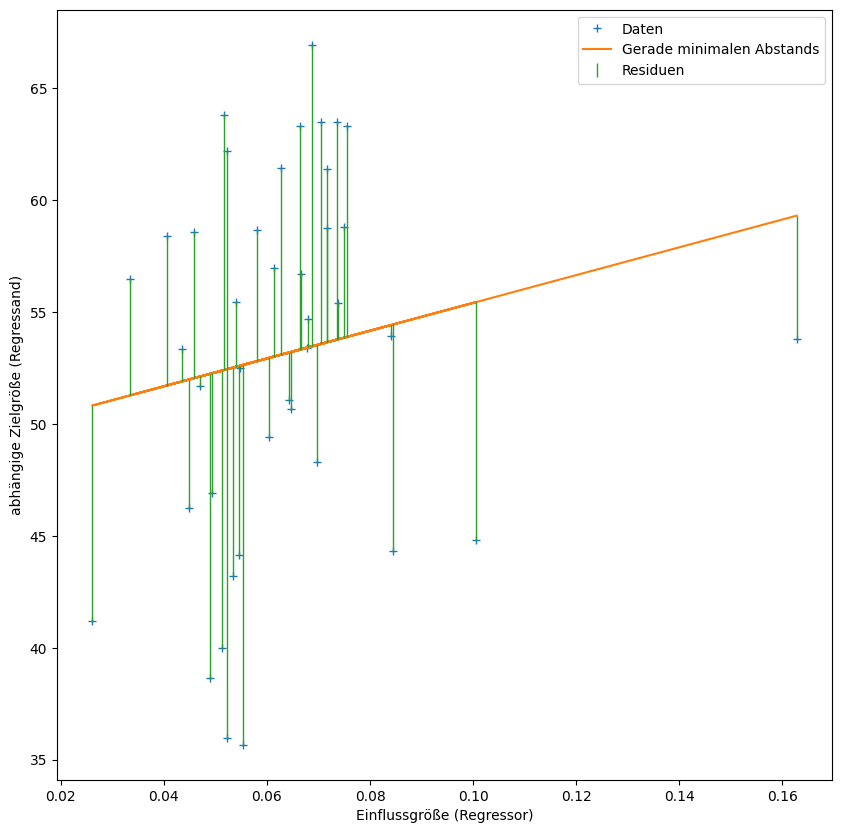

In [13]:
fig, ax = plt.subplots(figsize=(10,10))
ax.plot(x, y, "+", label="Daten")
ax.plot(x, f(x, beta_0, beta_1), label="Gerade minimalen Abstands")
yerr = np.stack((np.maximum(np.zeros_like(y), y - f(x, beta_0, beta_1)),
                 -np.minimum(np.zeros_like(y), y - f(x, beta_0, beta_1))))
ax.errorbar(x, y,
            yerr=yerr,
            linewidth=0, elinewidth=1,
            label="Residuen")
ax.set_xlabel("Einflussgröße (Regressor)")
ax.set_ylabel("abhängige Zielgröße (Regressand)")
ax.legend()
plt.show()

In [14]:
linregress_result = linregress(x, y)
slope, intercept, r, p, se = linregress_result
print("slope is %f" % slope)
assert np.isclose(slope, beta_1)
print("y-intercept is %f" % intercept)
assert np.isclose(intercept, beta_0)
print("correlation coefficient is %f" % r)
print("p-value is %.32f" % p)
print("squared error is %f" % se)

slope is 62.133670
y-intercept is 49.199263
correlation coefficient is 0.161250
p-value is 0.31384719290472717911910649490892
squared error is 60.894039


In [15]:
X_all = df[['trefferquote']]
y_all = df['wahlbeteiligung'] * 100

regressor = LinearRegression()
regressor.fit(X_all, y_all)
y_pred_all = regressor.predict(X_all)

r2 = r2_score(y_all, y_pred_all)
print(f"R^2 (Sklearn): {r2:.6f}")

# Überprüfung der Identität
assert np.isclose(r2, r**2)

R^2 (Sklearn): 0.026001


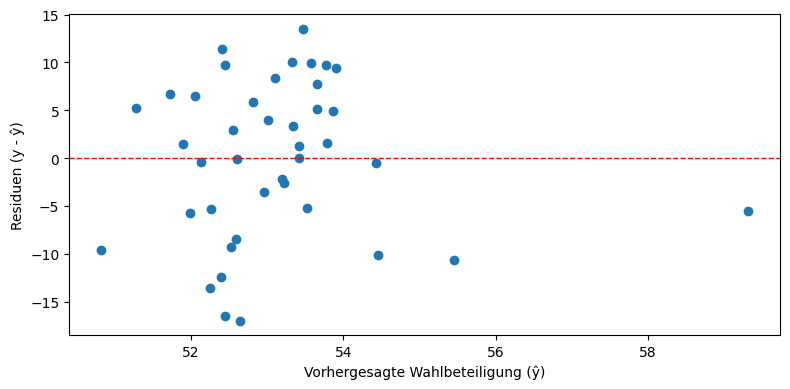

In [16]:
# Vorhersagen und Residuen berechnen
y_hat = f(x, beta_0, beta_1)
residuals = y - y_hat

fig, ax = plt.subplots(figsize=(8, 4))

# Residuen gegen vorhergesagte Werte
ax.scatter(y_hat, residuals)
ax.axhline(0, color='red', linestyle='--', linewidth=1)

ax.set_xlabel("Vorhergesagte Wahlbeteiligung (ŷ)")
ax.set_ylabel("Residuen (y - ŷ)")

plt.tight_layout()
plt.show()